# 03 - Predictive modelling of lead time
Linear Regression (baseline), Random Forest and Gradient Boosting; 80/20 split + 5-fold CV. Selection rule: lowest holdout RMSE, preferring the simpler model when within 2%.

Before modelling, a **signal diagnostic** shows how much of the lead-time variance each driver explains.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # notebooks/<stage>/ -> project root
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from src import config as C
from src import modeling

In [2]:
prepared = pd.read_csv(C.PROCESSED / 'orders_prepared.csv')
diag = modeling.signal_diagnostics(prepared)
diag.round(3)

,driver,type,variance_explained_pct
0,Ship Mode,categorical,66.461
1,Product Name,categorical,0.169
2,Origin Factory,categorical,0.131
3,Region,categorical,0.083
4,Division,categorical,0.065
5,Units,numeric (rho^2),0.032
6,Sales,numeric (rho^2),0.026
7,Country/Region,categorical,0.018
8,Unit Price,numeric (rho^2),0.011
9,Order Month,numeric (rho^2),0.005


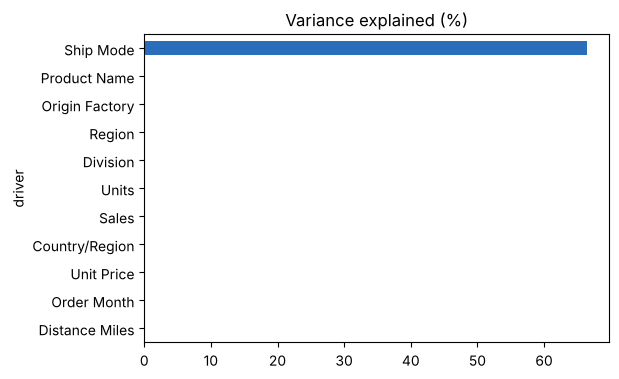

In [3]:
diag.sort_values('variance_explained_pct').plot.barh(x='driver', y='variance_explained_pct', legend=False, color='#2a6ebb', figsize=(6,4), title='Variance explained (%)'); plt.show()

In [4]:
bundle = modeling.train_and_select(prepared)
bundle['metrics'].round(3)

,Model,CV RMSE,Holdout RMSE,Holdout MAE,Holdout R2,Selected
0,Linear Regression,1.022,1.003,0.801,0.671,True
1,Random Forest,1.017,0.991,0.799,0.679,False
2,Gradient Boosting,1.016,0.994,0.803,0.677,False


In [5]:
print('Selected:', bundle['model_name'], '| holdout R2 =', round(bundle['holdout_r2'], 3))
bundle['importance'].round(4)

Selected: Linear Regression | holdout R2 = 0.671


,feature,rmse_increase,std
0,Ship Mode,1.2610,0.0242
1,Country/Region,0.0028,0.0006
2,Order Month,0.0016,0.0007
3,Product Name,0.0011,0.0007
4,Unit Price,0.0004,0.0003
5,Sales,0.0003,0.0003
6,Distance Miles,0.0002,0.0003
7,Origin Factory,0.0002,0.0004
8,Division,-0.0001,0.0001
9,Region,-0.0004,0.0005


**Reading the result.** Ship mode explains ~two thirds of the variance; factory, region, product and distance each explain well under 1%. All three models therefore score almost identically (RMSE ~1.0 day), and the baseline linear model is selected. Because every product ships from exactly one factory historically, factory identity cannot be separated from product - so the simulator adds an explicit distance-driven transit/freight component (see notebook 05).

In [6]:
modeling.save_bundle(bundle)